In [ ]:
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from x5uplift.config import CUTOFF, DATA_INTERIM, PRODUCTS_CSV, X5_FILES
from x5uplift import plotting as P

pd.set_option("display.width", 140)
P.set_style()

con = duckdb.connect()
con.execute("SET memory_limit='4GB'")

# Register each parquet file as a view: clients, train, purchases
for name, meta in X5_FILES.items():
    path = (DATA_INTERIM / meta["parquet"]).as_posix()
    con.execute(f"CREATE OR REPLACE VIEW {name} AS SELECT * FROM read_parquet('{path}')")

# Product reference table, read straight from CSV. All ids stay text, numbers are cast explicitly.
con.execute(f"""
CREATE OR REPLACE VIEW products AS
SELECT
    product_id, level_1, level_2, level_3, level_4,
    TRY_CAST(segment_id AS DOUBLE)        AS segment_id,
    brand_id, vendor_id,
    TRY_CAST(netto AS DOUBLE)             AS netto,
    TRY_CAST(is_own_trademark AS INTEGER) AS is_own_trademark,
    TRY_CAST(is_alcohol AS INTEGER)       AS is_alcohol
FROM read_csv('{PRODUCTS_CSV.as_posix()}', all_varchar = true)
""")

def q(sql):
    """Run a SQL query and return the result as a pandas DataFrame."""
    return con.execute(sql).df()

q("""
SELECT 'clients' AS table_name, COUNT(*) AS n_rows FROM clients
UNION ALL SELECT 'train', COUNT(*) FROM train
UNION ALL SELECT 'purchases', COUNT(*) FROM purchases
UNION ALL SELECT 'products', COUNT(*) FROM products
""")

,table_name,n_rows
0,clients,400162
1,train,200039
2,purchases,45786568


In [11]:
q("""
WITH history_end AS (
    SELECT MAX(transaction_datetime) AS ts FROM purchases
)
SELECT
    t.treatment_flg,
    COUNT(*) AS n_clients,
    AVG(CASE WHEN c.first_redeem_date IS NULL THEN 1 ELSE 0 END) AS share_never_redeemed,
    AVG(CASE WHEN c.first_redeem_date > h.ts THEN 1 ELSE 0 END) AS share_first_redeem_after_history,
    AVG(CASE WHEN c.first_redeem_date <= h.ts THEN 1 ELSE 0 END) AS share_first_redeem_before_end
FROM train AS t
JOIN clients AS c USING (client_id)
CROSS JOIN history_end AS h
GROUP BY t.treatment_flg
ORDER BY t.treatment_flg
""")

,treatment_flg,n_clients,share_never_redeemed,share_first_redeem_after_history,share_first_redeem_before_end
0,0,100058,0.091027,0.111036,0.797937
1,1,99981,0.084396,0.114922,0.800682


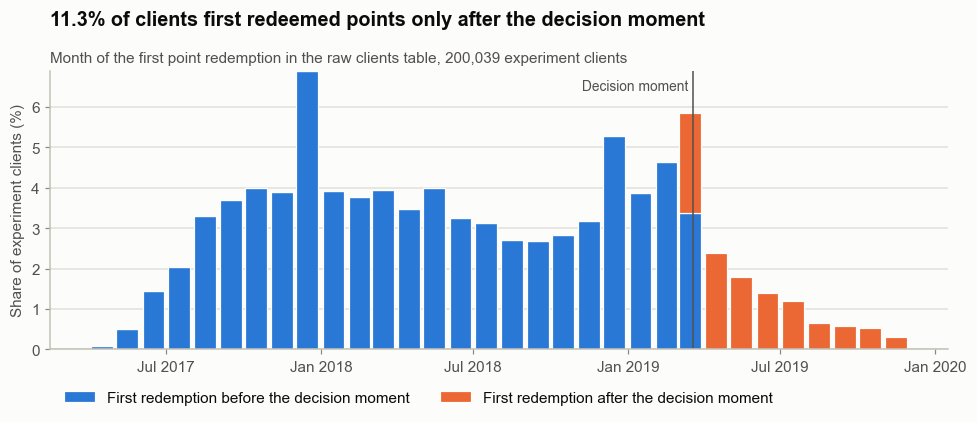

In [12]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

redeem = q(f"""
SELECT
    DATE_TRUNC('month', c.first_redeem_date)        AS month,
    c.first_redeem_date > TIMESTAMP '{CUTOFF}'      AS after_cutoff,
    COUNT(*)                                        AS n
FROM train AS t
JOIN clients AS c USING (client_id)
WHERE c.first_redeem_date IS NOT NULL
GROUP BY 1, 2
ORDER BY 1, 2
""")
n_train = q("SELECT COUNT(*) AS n FROM train")["n"][0]
redeem["pct"] = redeem["n"] / n_train * 100

wide = redeem.pivot(index="month", columns="after_cutoff", values="pct").fillna(0)
before = wide[False] if False in wide else 0
after = wide[True] if True in wide else 0
x = wide.index + pd.Timedelta(days=15)  # centre each bar inside its month

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(x, before, width=26, color=P.BLUE, edgecolor=P.SURFACE, linewidth=0.8,
       label="First redemption before the decision moment")
ax.bar(x, after, width=26, bottom=before, color=P.ORANGE, edgecolor=P.SURFACE, linewidth=0.8,
       label="First redemption after the decision moment")
cutoff_ts = pd.Timestamp(CUTOFF)
ax.axvline(cutoff_ts, color=P.INK_2, linewidth=1)
ax.text(cutoff_ts, ax.get_ylim()[1] * 0.97, "Decision moment ", ha="right", va="top",
        fontsize=9, color=P.INK_2)
ax.set_ylabel("Share of experiment clients (%)")
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.1), ncol=2)
P.titles(ax, f"{after.sum():.1f}% of clients first redeemed points only after the decision moment",
         f"Month of the first point redemption in the raw clients table, {n_train:,} experiment clients")
fig.tight_layout()
P.save(fig, "01_redeem_date_leak")
plt.show()

In [13]:
q("""
WITH per_txn AS (
    SELECT
        transaction_id,
        COUNT(*)                                AS n_items,
        COUNT(DISTINCT client_id)               AS n_clients,
        COUNT(DISTINCT transaction_datetime)    AS n_datetimes,
        COUNT(DISTINCT store_id)                AS n_stores,
        COUNT(DISTINCT purchase_sum)            AS n_purchase_sums,
        COUNT(DISTINCT regular_points_received) AS n_points_values,
        MAX(purchase_sum)                       AS purchase_sum,
        SUM(trn_sum_from_iss)                   AS iss_sum,
        SUM(trn_sum_from_iss) + COALESCE(SUM(trn_sum_from_red), 0) AS iss_red_sum
    FROM purchases
    GROUP BY transaction_id
)
SELECT
    COUNT(*)                                                       AS n_transactions,
    AVG(n_items)                                                   AS avg_items_per_txn,
    AVG(CASE WHEN n_clients > 1 THEN 1 ELSE 0 END)                 AS share_multi_client,
    AVG(CASE WHEN n_datetimes > 1 THEN 1 ELSE 0 END)               AS share_multi_datetime,
    AVG(CASE WHEN n_stores > 1 THEN 1 ELSE 0 END)                  AS share_multi_store,
    AVG(CASE WHEN n_purchase_sums > 1 THEN 1 ELSE 0 END)           AS share_varying_purchase_sum,
    AVG(CASE WHEN n_points_values > 1 THEN 1 ELSE 0 END)           AS share_varying_points,
    AVG(CASE WHEN ABS(iss_sum - purchase_sum) <= 1 THEN 1 ELSE 0 END)     AS share_iss_matches_total,
    AVG(CASE WHEN ABS(iss_red_sum - purchase_sum) <= 1 THEN 1 ELSE 0 END) AS share_iss_red_matches_total,
    MEDIAN(iss_red_sum / NULLIF(purchase_sum, 0))                  AS median_items_to_total_ratio
FROM per_txn
""").T

,0
n_transactions,8.045201e+06
avg_items_per_txn,5.691165e+00
share_multi_client,3.480336e-06
share_multi_datetime,3.480336e-06
share_multi_store,3.480336e-06
share_varying_purchase_sum,3.480336e-06
share_varying_points,3.356038e-06
share_iss_matches_total,8.719256e-01
share_iss_red_matches_total,8.760312e-01
median_items_to_total_ratio,1.000559e+00


In [14]:
daily = q("""
WITH daily AS (
    SELECT
        t.treatment_flg,
        CAST(p.transaction_datetime AS DATE) AS day,
        COUNT(DISTINCT p.transaction_id)     AS n_txn
    FROM purchases AS p
    JOIN train AS t USING (client_id)
    WHERE p.transaction_datetime >= TIMESTAMP '2019-02-25'
    GROUP BY 1, 2
),
group_size AS (
    SELECT treatment_flg, COUNT(*) AS n_clients FROM train GROUP BY 1
)
SELECT
    d.day,
    MAX(CASE WHEN d.treatment_flg = 0 THEN d.n_txn * 1000.0 / g.n_clients END) AS txn_per_1000_control,
    MAX(CASE WHEN d.treatment_flg = 1 THEN d.n_txn * 1000.0 / g.n_clients END) AS txn_per_1000_treatment
FROM daily AS d
JOIN group_size AS g USING (treatment_flg)
GROUP BY d.day
ORDER BY d.day
""")
daily["ratio_treatment_to_control"] = daily["txn_per_1000_treatment"] / daily["txn_per_1000_control"]
daily.round(3)

,day,txn_per_1000_control,txn_per_1000_treatment,ratio_treatment_to_control
0,2019-02-25,213.886,216.451,1.012
1,2019-02-26,196.006,200.048,1.021
2,2019-02-27,222.631,223.763,1.005
3,2019-02-28,214.036,212.640,0.993
4,2019-03-01,222.421,225.213,1.013
5,2019-03-02,212.427,216.641,1.020
6,2019-03-03,193.828,195.197,1.007
7,2019-03-04,217.974,215.761,0.990
8,2019-03-05,214.366,215.641,1.006
9,2019-03-06,215.625,215.621,1.000


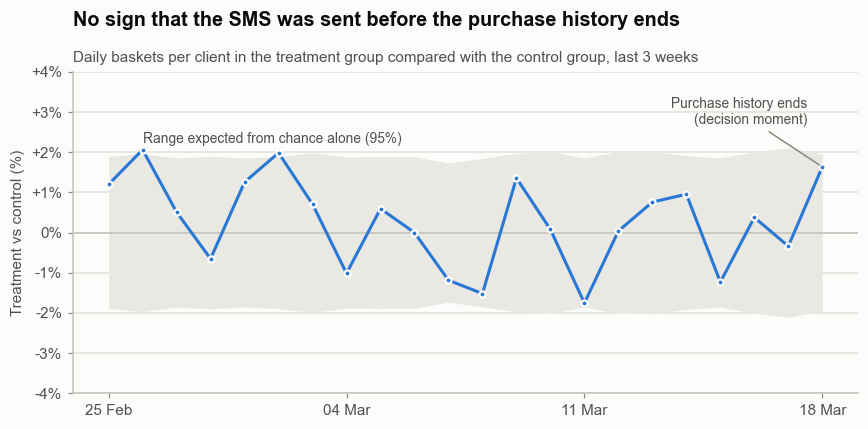

In [15]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

n_groups = q("SELECT treatment_flg, COUNT(*) AS n FROM train GROUP BY 1").set_index("treatment_flg")["n"]
n_c = daily["txn_per_1000_control"] * n_groups[0] / 1000    # daily baskets, control
n_t = daily["txn_per_1000_treatment"] * n_groups[1] / 1000  # daily baskets, treatment
diff_pct = (daily["ratio_treatment_to_control"] - 1) * 100
# 95% range for the difference if only chance were at work (Poisson approximation)
band_pct = 1.96 * np.sqrt(1 / n_c + 1 / n_t) * 100

fig, ax = plt.subplots(figsize=(8, 4))
ax.fill_between(daily["day"], -band_pct, band_pct, color=P.NEUTRAL_FILL, linewidth=0)
ax.axhline(0, color=P.AXIS, linewidth=1)
ax.plot(daily["day"], diff_pct, color=P.TREATMENT, marker="o", markersize=4,
        markeredgecolor=P.SURFACE, markeredgewidth=1.5)
ax.text(daily["day"].iloc[1], band_pct.iloc[1] + 0.25, "Range expected from chance alone (95%)",
        fontsize=9, color=P.INK_2)
ax.annotate("Purchase history ends\n(decision moment)", xy=(daily["day"].iloc[-1], diff_pct.iloc[-1]),
            xytext=(-10, 28), textcoords="offset points", ha="right", fontsize=9, color=P.INK_2,
            arrowprops=dict(arrowstyle="-", color=P.MUTED, linewidth=1))
ax.set_ylim(-4, 4)
ax.set_ylabel("Treatment vs control (%)")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:+.0f}%" if v else "0%")
ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
P.titles(ax, "No sign that the SMS was sent before the purchase history ends",
         "Daily baskets per client in the treatment group compared with the control group, last 3 weeks")
fig.tight_layout()
P.save(fig, "01_sms_timing_check")
plt.show()

In [16]:
q(f"""
SELECT
    (SELECT MAX(transaction_datetime) FROM purchases) = TIMESTAMP '{CUTOFF}' AS cutoff_matches_history_end,
    (SELECT COUNT(*) FROM clients WHERE first_issue_date > TIMESTAMP '{CUTOFF}') AS n_cards_issued_after_cutoff
""")

,cutoff_matches_history_end,n_cards_issued_after_cutoff
0,True,0


In [17]:
age_bands = q("""
SELECT
    CASE
        WHEN age < 0    THEN '01: negative'
        WHEN age < 14   THEN '02: 0-13'
        WHEN age < 18   THEN '03: 14-17'
        WHEN age < 25   THEN '04: 18-24'
        WHEN age < 35   THEN '05: 25-34'
        WHEN age < 45   THEN '06: 35-44'
        WHEN age < 55   THEN '07: 45-54'
        WHEN age < 65   THEN '08: 55-64'
        WHEN age < 80   THEN '09: 65-79'
        WHEN age <= 100 THEN '10: 80-100'
        ELSE                 '11: over 100'
    END AS age_band,
    COUNT(*) AS n_clients,
    ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct
FROM clients
GROUP BY 1
ORDER BY 1
""")

odd_values = q("""
SELECT age, COUNT(*) AS n_clients
FROM clients
WHERE age < 14 OR age > 100
GROUP BY age
ORDER BY n_clients DESC
LIMIT 15
""")

display(age_bands)
display(odd_values)

,age_band,n_clients,pct
0,01: negative,96,0.02
1,02: 0-13,634,0.16
2,03: 14-17,4822,1.21
3,04: 18-24,27290,6.82
4,05: 25-34,76077,19.01
5,06: 35-44,85019,21.25
6,07: 45-54,68538,17.13
7,08: 55-64,77127,19.27
8,09: 65-79,53149,13.28
9,10: 80-100,6361,1.59


,age,n_clients
0,115,405
1,119,397
2,13,137
3,12,93
4,11,84
5,10,61
6,9,51
7,1,48
8,0,42
9,8,33


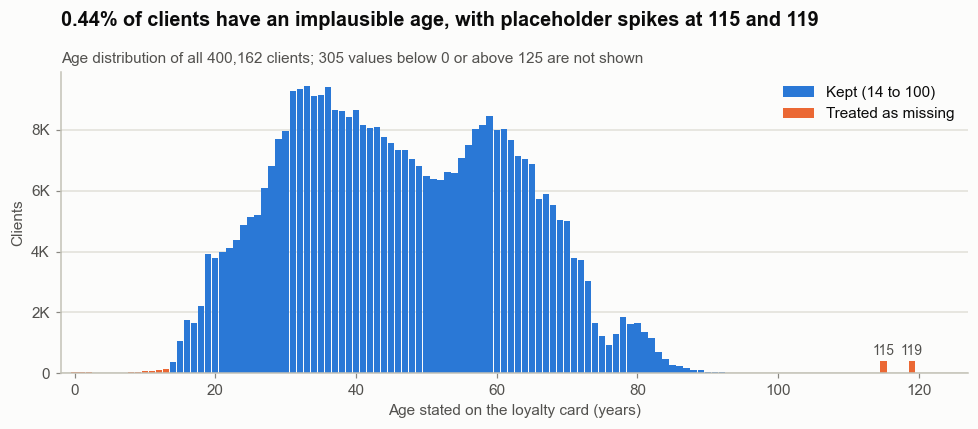

In [18]:
from x5uplift.config import AGE_MIN, AGE_MAX

ages_df = q("SELECT age, COUNT(*) AS n FROM clients WHERE age BETWEEN 0 AND 125 GROUP BY age ORDER BY age")
n_hidden = q("SELECT COUNT(*) AS n FROM clients WHERE age < 0 OR age > 125")["n"][0]
n_clients = q("SELECT COUNT(*) AS n FROM clients")["n"][0]

invalid = (ages_df["age"] < AGE_MIN) | (ages_df["age"] > AGE_MAX)
n_invalid = int(ages_df.loc[invalid, "n"].sum()) + n_hidden
pct_invalid = 100 * n_invalid / n_clients
spikes = ages_df[ages_df["age"] > AGE_MAX].nlargest(2, "n")["age"].sort_values().tolist()

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(ages_df.loc[~invalid, "age"], ages_df.loc[~invalid, "n"], width=0.9, color=P.BLUE,
       label=f"Kept ({AGE_MIN} to {AGE_MAX})")
ax.bar(ages_df.loc[invalid, "age"], ages_df.loc[invalid, "n"], width=0.9, color=P.ORANGE,
       label="Treated as missing")
for a in spikes:
    v = ages_df.loc[ages_df["age"] == a, "n"].iloc[0]
    ax.annotate(f"{a}", xy=(a, v), xytext=(0, 4), textcoords="offset points",
                ha="center", fontsize=9, color=P.INK_2)
ax.set_xlim(-2, 127)
ax.set_xlabel("Age stated on the loyalty card (years)")
ax.set_ylabel("Clients")
ax.yaxis.set_major_formatter(lambda v, _: f"{v/1000:.0f}K" if v >= 1000 else f"{v:.0f}")
ax.legend(loc="upper right")
P.titles(ax, f"{pct_invalid:.2f}% of clients have an implausible age, with placeholder spikes at {spikes[0]} and {spikes[1]}",
         f"Age distribution of all {n_clients:,} clients; {n_hidden:,} values below 0 or above 125 are not shown")
fig.tight_layout()
P.save(fig, "01_age_cleaning")
plt.show()

In [19]:
gender = q("""
SELECT gender, COUNT(*) AS n_clients,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct
FROM clients
GROUP BY 1
ORDER BY 1
""")

baskets = q("""
WITH b AS (
    SELECT client_id, transaction_id,
           MAX(purchase_sum) AS basket_sum,
           COUNT(*)          AS n_items
    FROM purchases
    GROUP BY client_id, transaction_id
)
SELECT
    COUNT(*)                                          AS n_baskets,
    AVG(CASE WHEN basket_sum = 0 THEN 1 ELSE 0 END)   AS share_zero_sum,
    QUANTILE_CONT(basket_sum, [0.01, 0.5, 0.99, 0.999]) AS basket_sum_q01_q50_q99_q999,
    MAX(basket_sum)                                   AS max_basket_sum,
    QUANTILE_CONT(n_items, [0.5, 0.99])               AS items_q50_q99,
    MAX(n_items)                                      AS max_items
FROM b
""")

quantity = q("""
SELECT
    QUANTILE_CONT(product_quantity, [0.5, 0.99, 0.999, 0.9999])               AS qty_q50_q99_q999_q9999,
    AVG(CASE WHEN product_quantity = 0 THEN 1 ELSE 0 END)                    AS share_zero_qty,
    AVG(CASE WHEN product_quantity <> FLOOR(product_quantity) THEN 1 ELSE 0 END) AS share_fractional_qty
FROM purchases
""")

display(gender)
display(baskets.T)
display(quantity.T)

,gender,n_clients,pct
0,F,147649,36.90
1,M,66807,16.69
2,U,185706,46.41


,0
n_baskets,8045229
share_zero_sum,0.00007
basket_sum_q01_q50_q99_q999,"[23.0, 282.0, 2372.07, 4471.947559999972]"
max_basket_sum,35149.04
items_q50_q99,"[4.0, 24.0]"
max_items,116


,0
qty_q50_q99_q999_q9999,"[1.0, 5.0, 11.0, 30.0]"
share_zero_qty,0.059128
share_fractional_qty,0.0


In [20]:
import numpy as np
from x5uplift.config import SPLITS_PATH
from x5uplift.splits import make_splits

labeled = q("SELECT client_id, treatment_flg, target FROM train")
splits = make_splits(labeled)

# Same seed and same input must give exactly the same split
assert splits.equals(make_splits(labeled)), "split is not reproducible"

SPLITS_PATH.parent.mkdir(parents=True, exist_ok=True)
splits.to_parquet(SPLITS_PATH, index=False)

part = np.where(splits["is_test"], "test", "fold_" + splits["fold"].astype(str))
check = splits.assign(part=part).groupby("part").agg(
    n_clients=("client_id", "size"),
    treatment_share=("treatment_flg", "mean"),
    target_rate=("target", "mean"),
)
check["share_of_all"] = check["n_clients"] / len(splits)
check.round(4)

,n_clients,treatment_share,target_rate,share_of_all
part,,,,
fold_0,28007,0.4998,0.6199,0.14
fold_1,28007,0.4998,0.6199,0.14
fold_2,28005,0.4998,0.6199,0.14
fold_3,28005,0.4998,0.6199,0.14
fold_4,28003,0.4998,0.6199,0.14
test,60012,0.4998,0.6199,0.30
